# Metamodel case generation

Workflow:

1. Load **goals** from the case JSON → `simulations.goals_file`.
2. Generate **Latin Hypercube** cases per goal (`tp`, `wd`, `ds`, `zs`).
3. Build SnapWave case directories from `templates-metamodel`.
4. Run cases (optional) and postprocess to per-goal NetCDF files.

Paths and bounds come from the case JSON → `simulations`.

In [1]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

from utils.config import PATHS, SIMULATIONS, goals_for_snapwave, load_goals, resolve
from utils.simulation import lhs_cases as sim
from utils.simulation.snapwave_wrappers import SnapWaveMetaModelWrapper

## Configuration

In [2]:
templates_dir = resolve(SIMULATIONS["metamodel_templates"])
cases_dir = resolve(SIMULATIONS["metamodel_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])

print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"samples   : {SIMULATIONS['num_samples_per_goal']} per goal")

goals     : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Goals/Netherlands_Goals.json
templates : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/templates-metamodel
cases     : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SnapWave_CASES_Metamodel
mesh      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/GRID/UGdcsm-fm_100m2coast3d_v3_era5bnd_net.nc
samples   : 500 per goal


## LHS cases

In [3]:
raw_goals = load_goals()

cases_df = sim.generate_cases(raw_goals)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df.head()

,goal,tp,dir,spr,wl
0,1,12.213669,250.438911,18.939314,1.302719
1,1,8.383269,250.143844,13.775162,-2.609729
2,1,6.444611,297.814803,13.077691,0.370466
3,1,5.190768,15.340020,42.685319,3.339651
4,1,7.184247,177.148457,21.310096,2.068328


In [4]:
import numpy as np

# Add a new column called save_map with 5% True
cases_df["save_map"] = np.random.choice(
    [True, False], size=len(cases_df), p=[0.05, 0.95]
)
cases_df.head(20)

,goal,tp,dir,spr,wl,save_map
0,1,12.213669,250.438911,18.939314,1.302719,False
1,1,8.383269,250.143844,13.775162,-2.609729,False
2,1,6.444611,297.814803,13.077691,0.370466,False
3,1,5.190768,15.340020,42.685319,3.339651,False
4,1,7.184247,177.148457,21.310096,2.068328,False
5,1,11.618990,127.305025,38.181303,-0.755730,False
6,1,10.493074,138.259731,21.632372,-1.529876,False
7,1,2.591502,327.178767,27.794586,-1.373622,False
8,1,10.138542,321.683350,10.274056,1.891158,False
9,1,4.274891,310.606160,10.375578,-1.358873,False


In [5]:
cases_df.groupby(["goal", "save_map"])[["tp"]].count()

tp
goal save_map     
1    False     476
     True       24
2    False     468
     True       32
3    False     479
     True       21
4    False     470
     True       30
5    False     472
     True       28
6    False     482
     True       18
7    False     481
     True       19
8    False     475
     True       25
9    False     458
     True       42
10   False     477
     True       23

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + direction-range bars per goal; right side = text summary.
Review this before `build_cases()`.

In [6]:
wrapper = SnapWaveMetaModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

In [7]:
wrapper.output_sites_df

,lon,lat,source,source_id,source_label,depth,name
0,7.132907,53.728084,isobath,5m_0,5m,-5.0,NaN
1,7.115667,53.723900,isobath,5m_1,5m,-5.0,NaN
2,7.130204,53.738395,isobath,5m_2,5m,-5.0,NaN
3,6.959663,53.686278,isobath,5m_3,5m,-5.0,NaN
4,6.805006,53.648283,isobath,5m_4,5m,-5.0,NaN
...,...,...,...,...,...,...,...
1229,4.057020,52.549220,buoy,buoy_IJmuidenMunitiestort_1,waves,NaN,"IJmuiden, munitiestort, 1"
1230,4.556780,52.806850,buoy,buoy_PettenMeetraai01,waves,NaN,"Petten, meetraai 01"
1231,4.996000,53.320720,buoy,buoy_StortemelkWest,waves,NaN,"Stortemelk, west"
1232,6.366670,53.618060,buoy,buoy_WestereemsWest,waves,NaN,"Westereems, west"


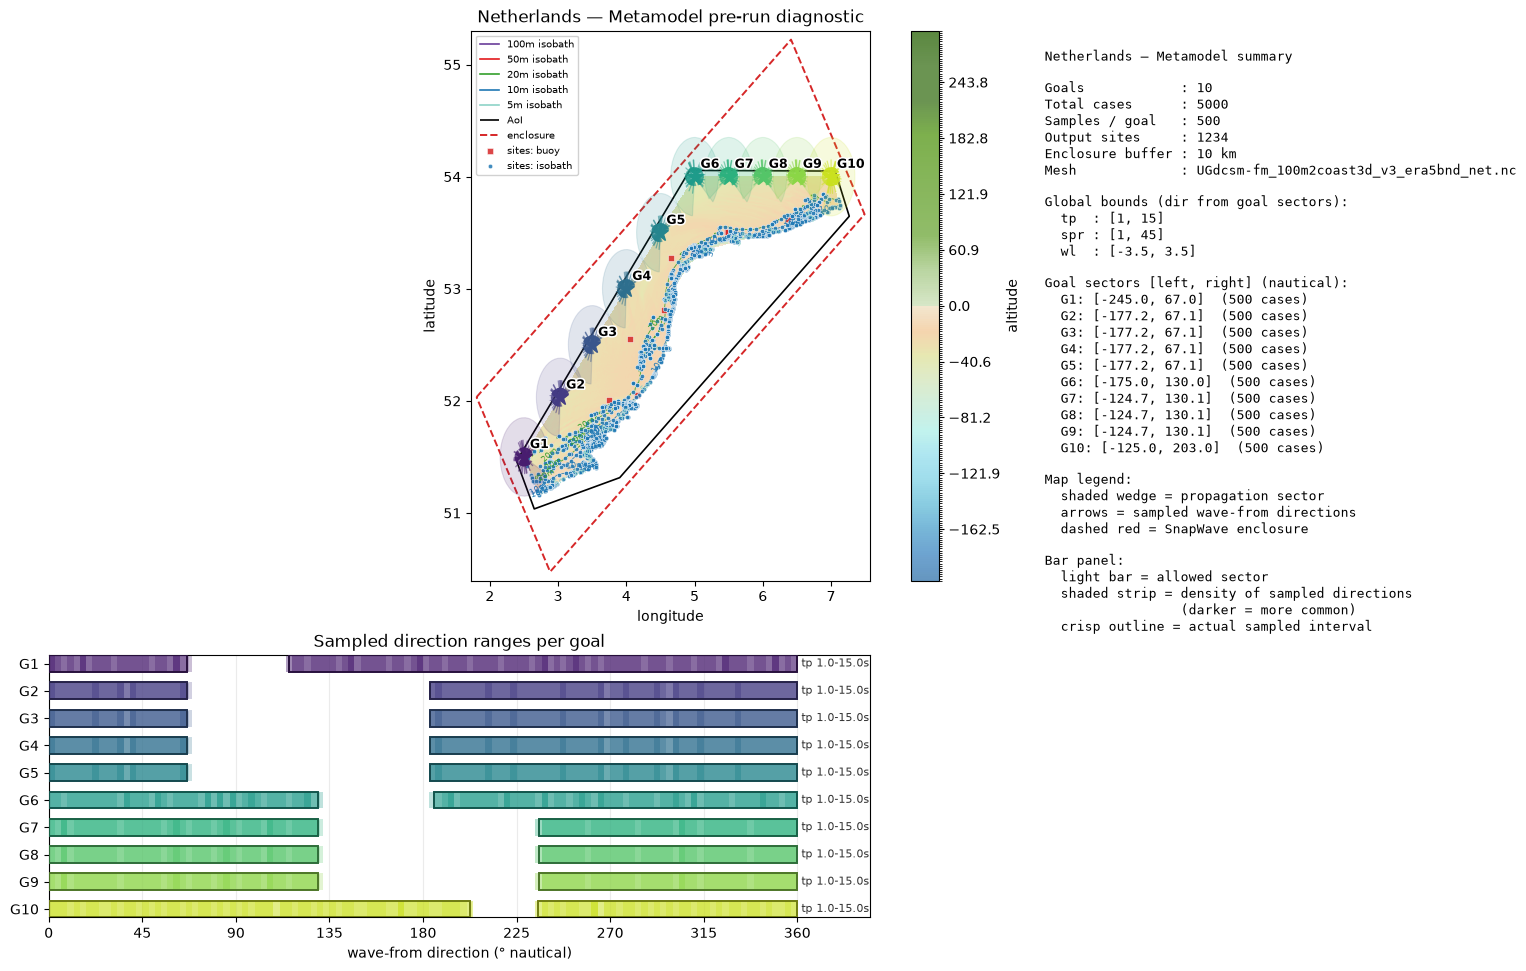

In [8]:
fig = wrapper.plot_configuration()
# fig.savefig("metamodel_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [9]:
wrapper.load_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [10]:
# Save all cases directories to a text file for sbatch array submission
# wrapper.cases_dir_to_txt()

In [11]:
# wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [12]:
cases_status = wrapper.monitor_cases(value_counts="simple")
cases_status

Status  
FINISHED    5000
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: full-width domain `tripcolor` map (or overview fallback)
- bottom 2×2: `hs`, `tp`, `dir`, `spr` at output sites
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"})`.

Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


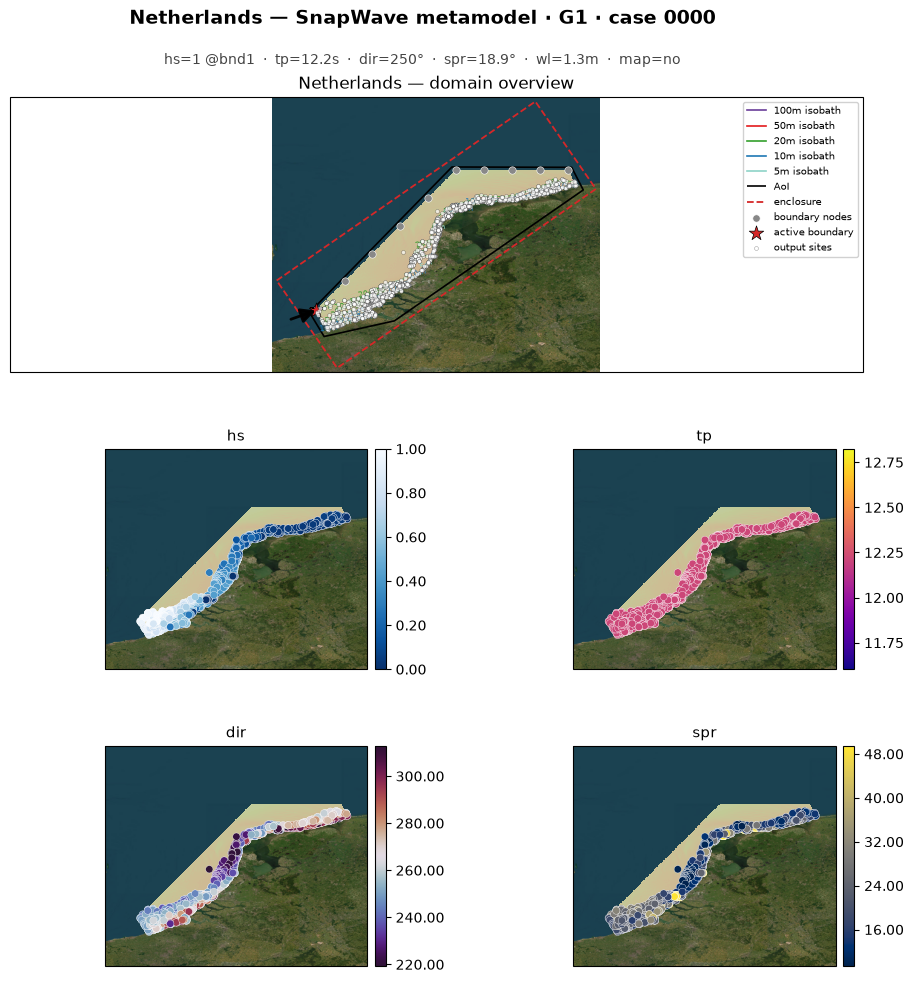

In [16]:
from utils.viz.snapwave_case_plots import CasePlotStyle

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"}
)
wrapper.plot_case(goal=1, case_num=0, style=style, show_satellite=True);

In [13]:
wrapper.postprocess_cases()

'Done'